# Data Mining Lab Assignment 2
**Build a Recommender System using a Medallion Data Lake**

Rebant Pratap Singh | LCS2023003  
Dataset: Book-Crossing

In [1]:
from collections import Counter
from functools import lru_cache
from html import unescape
from itertools import islice
from pathlib import Path
from zipfile import ZipFile, is_zipfile

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.preprocessing import normalize

## Step 1: Set Up the Data Lake and Build the Bronze Layer

In [2]:
BRONZE, SILVER, GOLD = map(Path, ["bronze", "silver", "gold"])
for folder in (BRONZE, SILVER, GOLD):
    folder.mkdir(exist_ok=True)

archive = Path("book-crossings.zip")
if not is_zipfile(archive):
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Place book-crossings.zip beside the notebook, then rerun this cell.") from None
    print("Choose the book-crossings.zip file provided with the assignment.")
    files.upload_file(str(archive))

if not is_zipfile(archive):
    raise ValueError("Choose the original ZIP file, then rerun this cell.")
print("Dataset ready:", archive.name)

Choose the book-crossings.zip file provided with the assignment.


Saved book-crossings.zip to /content/book-crossings.zip
Dataset ready: book-crossings.zip


In [3]:
members = {"users": "BX-Users.csv", "books": "BX-Books.csv", "ratings": "BX-Book-Ratings.csv"}
ingested = pd.Timestamp.now(tz="UTC")
with ZipFile(archive) as source:
    paths = {Path(member).name: member for member in source.namelist()}
    missing = set(members.values()) - paths.keys()
    if missing:
        raise ValueError(f"Missing CSV files: {sorted(missing)}. Replace book-crossings.zip with the assignment ZIP.")
    for name, member in members.items():
        with source.open(paths[member]) as stream:
            frame = pd.read_csv(stream, sep=";", encoding="latin-1", escapechar="\\",
                                dtype="string", keep_default_na=False, on_bad_lines="error")
        frame["ingestion_timestamp"] = ingested
        frame.to_parquet(BRONZE / f"{name}.parquet", index=False)
        print(f"{name:7} {len(frame):>10,} rows   {len(frame.columns)} Bronze columns")
del frame

users      278,858 rows   4 Bronze columns
books      271,379 rows   9 Bronze columns
ratings  1,149,780 rows   4 Bronze columns


## Step 2: Explore the Bronze Data (EDA)

In [4]:
def read_layer(folder, name):
    return pd.read_parquet(folder / f"{name}.parquet")

users_b, books_b, ratings_b = [read_layer(BRONZE, name) for name in members]
schema = []
for name, table in zip(members, (users_b, books_b, ratings_b)):
    for col in table:
        missing = table[col].isna() | table[col].isin(["", "NULL"])
        schema.append([name, len(table), len(table.columns), col, str(table[col].dtype), int(missing.sum())])
display(pd.DataFrame(schema, columns=["Table", "Rows", "Columns", "Field", "Bronze type", "Missing / NULL"]))

,Table,Rows,Columns,Field,Bronze type,Missing / NULL
0,users,278858,4,User-ID,string,0
1,users,278858,4,Location,string,0
2,users,278858,4,Age,string,110762
3,users,278858,4,ingestion_timestamp,"datetime64[us, UTC]",0
4,books,271379,9,ISBN,string,0
5,books,271379,9,Book-Title,string,0
6,books,271379,9,Book-Author,string,0
7,books,271379,9,Year-Of-Publication,string,0
8,books,271379,9,Publisher,string,0
9,books,271379,9,Image-URL-S,string,0


The source fields are text, and Age has 110,762 missing values. In Silver I convert ages, years and ratings to numbers, fill missing ages and keep ISBNs as text.

In [5]:
raw_score = pd.to_numeric(ratings_b["Book-Rating"])
frequency = raw_score.value_counts().sort_index()
display(pd.DataFrame({"Recorded interactions": frequency,
                      "Share (%)": (100 * frequency / len(raw_score)).round(2)}).rename_axis("Rating"))

,Recorded interactions,Share (%)
Rating,,
0,716109,62.28
1,1770,0.15
2,2759,0.24
3,5996,0.52
4,8904,0.77
5,50974,4.43
6,36924,3.21
7,76457,6.65
8,103736,9.02


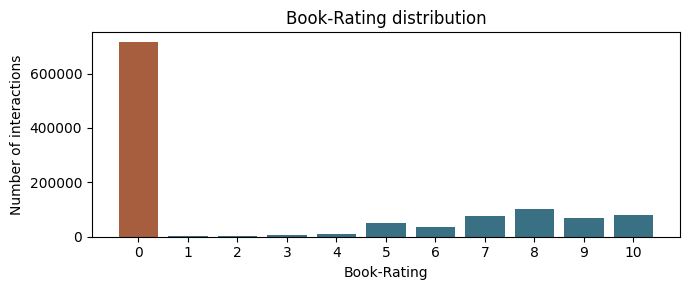

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(frequency.index, frequency.values, color=["#a75e3f"] + ["#397083"] * 10)
ax.set(title="Book-Rating distribution", xlabel="Book-Rating", ylabel="Number of interactions",
       xticks=range(11))
ax.ticklabel_format(axis="y", style="plain")
fig.tight_layout()
plt.show()

Zero accounts for 716,109 interactions (62.28%). I exclude these from the Silver ratings table but keep track of which books each user has already seen.

In [7]:
as_of_year = ingested.year
raw_age = pd.to_numeric(users_b["Age"], errors="coerce")
raw_year = pd.to_numeric(books_b["Year-Of-Publication"], errors="coerce")
distribution = pd.DataFrame({"Age": raw_age, "Publication year": raw_year}).describe().T
display(distribution[["min", "25%", "50%", "75%", "max"]])
print("Ages present but outside 5–100:", int((raw_age.notna() & ~raw_age.between(5, 100)).sum()))
print("Year zero:", int(raw_year.eq(0).sum()), "| Future:", int(raw_year.gt(as_of_year).sum()))

,min,25%,50%,75%,max
Age,0.0,24.0,32.0,44.0,244.0
Publication year,0.0,1989.0,1995.0,2000.0,2050.0


Ages present but outside 5–100: 1248
Year zero: 4619 | Future: 11


Ages range from 0 to 244 and publication years from 0 to 2050. In Silver I fill missing or invalid ages with the valid-age median of 32 and clear zero or future years.

In [8]:
activity = pd.DataFrame({
    label: ratings_b.groupby(key).size().describe(percentiles=[.25, .50, .75, .90])
    for label, key in [("Per observed user", "User-ID"), ("Per observed ISBN", "ISBN")]
})
display(activity.round(2))

,Per observed user,Per observed ISBN
count,105283.00,340556.00
mean,10.92,3.38
std,90.56,12.44
min,1.00,1.00
25%,1.00,1.00
50%,1.00,1.00
75%,4.00,2.00
90%,12.00,6.00
max,13602.00,2502.00


The median user and median book each have one recorded interaction. I compare minimum rating counts of 5, 8 and 10 in Silver.

In [9]:
valid_pair = ratings_b["User-ID"].isin(users_b["User-ID"]) & ratings_b["ISBN"].isin(books_b["ISBN"])
pairs = ratings_b.loc[valid_pair, ["User-ID", "ISBN"]].drop_duplicates()
possible = users_b["User-ID"].nunique() * books_b["ISBN"].nunique()
observed_pct = 100 * len(pairs) / possible
print(f"Matched recorded pairs: {len(pairs):,} / {possible:,} possible")
print(f"Density: {observed_pct:.6f}% | Sparsity: {100 - observed_pct:.6f}%")

Matched recorded pairs: 1,031,175 / 75,676,205,182 possible
Density: 0.001363% | Sparsity: 99.998637%


Only 0.001363% of possible user-book pairs have a recorded interaction. I keep matched pairs in Silver and store explicit ratings in a sparse matrix in Gold.

## Step 3: Clean the Data and Build the Silver Layer

In [10]:
def clean_text(series):
    return (series.astype("string").map(unescape, na_action="ignore").astype("string")
            .str.replace(r"\s+", " ", regex=True).str.strip().replace("", pd.NA))

def isbn_key(series):
    return series.astype("string").str.strip().str.upper()

In [11]:
# Users: remove duplicates, fix Age and split Location.
users = users_b.drop(columns="ingestion_timestamp").drop_duplicates().copy()
users["user_id"] = pd.to_numeric(users["User-ID"], errors="raise").astype("int32")
ages = pd.to_numeric(users["Age"], errors="coerce")
valid_age = ages.where(ages.between(5, 100))
users["age_imputed"] = valid_age.isna()
users["age"] = valid_age.fillna(valid_age.median()).astype("int16")
parts = users["Location"].str.rsplit(",", n=2, expand=True)
for i, col in enumerate(["city", "state", "country"]):
    users[col] = clean_text(parts[i]).str.casefold().replace(["n/a", '"n/a"', "null"], pd.NA)
users = users[["user_id", "city", "state", "country", "age", "age_imputed"]].drop_duplicates("user_id")

In [12]:
# Books: clean titles, authors, publishers and publication years.
books = books_b.drop(columns="ingestion_timestamp").drop_duplicates().copy()
books["isbn"] = isbn_key(books["ISBN"])
books["title"] = clean_text(books["Book-Title"])
books["author"] = clean_text(books["Book-Author"])
books["title_key"] = books["title"].str.casefold()
books["author_key"] = books["author"].str.casefold()
books["publisher"] = clean_text(books["Publisher"]).str.casefold()
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
books["year"] = year.where(year.between(1, as_of_year)).astype("Int16")
books = books[["isbn", "title", "author", "title_key", "author_key", "publisher", "year"]].drop_duplicates("isbn")
books["work_key"] = books.title_key.fillna(books.isbn) + " | " + books.author_key.fillna("")
work_by_isbn = books.set_index("isbn").work_key

In [13]:
# Book-Ratings: keep valid user and book IDs; separate explicit and implicit ratings.
events = ratings_b.drop(columns="ingestion_timestamp").drop_duplicates().copy()
events["isbn"] = isbn_key(events["ISBN"])
events["user_id"] = pd.to_numeric(events["User-ID"], errors="coerce")
events["rating"] = pd.to_numeric(events["Book-Rating"], errors="coerce")
events = events.loc[events["isbn"].isin(books["isbn"]) & events["user_id"].isin(users["user_id"]),
                    ["user_id", "isbn", "rating"]].copy()
events["user_id"] = events["user_id"].astype("int32")
implicit = events.loc[events["rating"].eq(0), ["user_id", "isbn"]].drop_duplicates()
explicit = events.loc[events["rating"].between(1, 10)].copy()
# A user/ISBN pair is one vote. A mean also handles conflicting explicit repeats.
explicit = explicit.groupby(["user_id", "isbn"], as_index=False, sort=True)["rating"].mean()
explicit["rating"] = explicit["rating"].astype("float32")
print(f"Linked explicit pairs: {len(explicit):,} | Linked zero-rated pairs: {len(implicit):,}")

Linked explicit pairs: 383,853 | Linked zero-rated pairs: 647,325


In [14]:
def stable_core(data, minimum):
    """Repeat the filter because removing books can lower a user's count."""
    while len(data):
        user_ok = data.groupby("user_id")["isbn"].transform("size").ge(minimum)
        book_ok = data.groupby("isbn")["user_id"].transform("size").ge(minimum)
        keep = user_ok & book_ok
        if keep.all():
            break
        data = data.loc[keep]
    return data.reset_index(drop=True)

MINIMUM = 8
choices = []
for floor in (5, MINIMUM, 10):
    sample = stable_core(explicit, floor)
    choices.append([floor, sample.user_id.nunique(), sample.isbn.nunique(), len(sample),
                    round(100 * len(sample) / len(explicit), 2)])
    if floor == MINIMUM:
        retained = sample
comparison = pd.DataFrame(choices, columns=["Minimum", "Users", "ISBNs", "Ratings", "Explicit pairs kept (%)"])
display(comparison.set_index("Minimum"))

,Users,ISBNs,Ratings,Explicit pairs kept (%)
Minimum,,,,
5,6858,9092,115332,30.05
8,2934,3481,62546,16.29
10,1820,2030,41469,10.80


I chose **8 ratings per user and per book**. A minimum of 5 keeps 9,092 books, 8 keeps 3,481, and 10 leaves 2,030. Eight keeps more books than ten while still giving each book at least eight ratings.

In [15]:
silver_users = users[users.user_id.isin(retained.user_id)].sort_values("user_id")
silver_books = books[books.isbn.isin(retained.isbn)].sort_values("isbn")
for name, frame in [("users", silver_users), ("books", silver_books), ("ratings", retained)]:
    frame.to_parquet(SILVER / f"{name}.parquet", index=False)
implicit.to_parquet(SILVER / "implicit_seen.parquet", index=False)

def seen_works(pairs):
    return pd.DataFrame({"user_id": pairs.user_id, "work_key": pairs.isbn.map(work_by_isbn)}).drop_duplicates()

seen_works(events).to_parquet(SILVER / "seen_works.parquet", index=False)

In [16]:
assert retained.groupby("user_id").size().min() >= MINIMUM
assert retained.groupby("isbn").size().min() >= MINIMUM
assert retained.rating.between(1, 10).all() and not retained.duplicated(["user_id", "isbn"]).any()
assert silver_users.age.between(5, 100).all() and silver_books.year.dropna().between(1, as_of_year).all()
print("Silver checks passed for keys, score range, age, year and both minimum counts.")

Silver checks passed for keys, score range, age, year and both minimum counts.


## Step 4: Build the Gold Layer

In [17]:
def make_matrix(data):
    readers = pd.Index(sorted(data.user_id.unique()), name="user_id")
    items = pd.Index(sorted(data.isbn.unique()), name="isbn")
    rows, cols = readers.get_indexer(data.user_id), items.get_indexer(data.isbn)
    values = data.rating.to_numpy(dtype=np.float32)
    matrix = sparse.csr_matrix((values, (rows, cols)), shape=(len(readers), len(items)))
    return matrix, readers, items

ratings = read_layer(SILVER, "ratings")
catalog = read_layer(SILVER, "books")
R, readers, items = make_matrix(ratings)
sparse.save_npz(GOLD / "user_book.npz", R)

In [18]:
# Book lookup and user IDs in matrix order.
lookup = catalog.set_index("isbn").loc[items, ["title", "author", "title_key", "work_key"]].reset_index()
lookup.insert(0, "book_col", np.arange(len(lookup)))
lookup.to_parquet(GOLD / "book_lookup.parquet", index=False)
pd.DataFrame({"user_row": np.arange(len(readers)), "user_id": readers}).to_parquet(GOLD / "user_lookup.parquet", index=False)

In [19]:
# User-level and book-level aggregates.
for key, label in [("user_id", "user"), ("isbn", "book")]:
    stats = ratings.groupby(key).rating.agg(average_rating="mean", rating_count="size")
    stats.reset_index().to_parquet(GOLD / f"{label}_stats.parquet", index=False)

history = read_layer(SILVER, "seen_works")
seen = history.loc[history.user_id.isin(readers) & history.work_key.isin(lookup.work_key)]
seen.to_parquet(GOLD / "seen.parquet", index=False)
print(f"{R.shape[0]:,} readers × {R.shape[1]:,} ISBNs | {R.nnz:,} stored scores")
print(f"Gold density: {100 * R.nnz / (R.shape[0] * R.shape[1]):.3f}%")
display(read_layer(GOLD, "book_stats").nlargest(3, "rating_count").merge(lookup[["isbn", "title"]], on="isbn"))

2,934 readers × 3,481 ISBNs | 62,546 stored scores
Gold density: 0.612%


,isbn,average_rating,rating_count,title
0,0316666343,8.224638,276,The Lovely Bones: A Novel
1,0385504209,8.563637,220,The Da Vinci Code
2,0312195516,8.454545,165,The Red Tent (Bestselling Backlist)


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

Each row of the transposed matrix represents a book. After L2 normalization, the dot product of two book rows is their cosine similarity.

In [20]:
class ItemModel:
    def __init__(self, matrix, reader_ids, book_ids, work_keys, seen_history):
        self.history = matrix.tocsr()
        self.vectors = normalize(matrix.T.tocsr(), norm="l2", axis=1)
        self.reader_ids = pd.Index(reader_ids)
        self.book_ids = pd.Index(book_ids)
        self.work = np.asarray(work_keys)
        self.rating_counts = np.asarray((matrix > 0).sum(axis=0)).ravel()
        # Column order is sorted ISBN, the deterministic tie breaker.
        self.popularity = np.argsort(-self.rating_counts, kind="stable")
        self.seen = seen_history.groupby("user_id").work_key.agg(set).to_dict()

    @lru_cache(maxsize=8192)
    def neighbors(self, book_col, k=40):
        dots = (self.vectors.getrow(book_col) @ self.vectors.T).tocsr()
        nonself = (dots.indices != book_col) & (dots.data > 0)
        ids, sims = dots.indices[nonself], dots.data[nonself]
        order = np.lexsort((ids, -sims))[:k]
        return list(zip(ids[order], sims[order]))

    def favorites(self, user_id):
        if user_id not in self.reader_ids:
            return []
        row = self.history.getrow(self.reader_ids.get_loc(user_id))
        return sorted(((int(i), float(r)) for i, r in zip(row.indices, row.data) if r >= 8),
                      key=lambda x: (-x[1], x[0]))

In [21]:
def distinct_works(work_keys, entries, n, excluded=()):
    seen_keys = set(excluded)
    def unseen():
        for entry in entries:
            key = work_keys[entry[0]]
            if key not in seen_keys:
                seen_keys.add(key)
                yield entry
    return list(islice(unseen(), n))

In [22]:
def rank_books(model, user_id, n=10, popularity_only=False):
    blocked = model.seen.get(user_id, set())
    if popularity_only:
        entries = ((i, int(model.rating_counts[i]), None) for i in model.popularity)
        return distinct_works(model.work, entries, n, blocked)
    scores, best = Counter(), {}
    for seed, rating in model.favorites(user_id):
        for item, sim in model.neighbors(seed):
            if model.work[item] in blocked:
                continue
            vote = rating / 10 * float(sim)
            scores[item] += vote
            if item not in best or vote > best[item][0]:
                best[item] = (vote, seed)
    ordered = sorted(scores, key=lambda i: (-scores[i], i))
    return distinct_works(model.work, ((i, scores[i], best[i][1]) for i in ordered), n)

In [23]:
R = sparse.load_npz(GOLD / "user_book.npz")
reader_axis = read_layer(GOLD, "user_lookup").sort_values("user_row").user_id
details = read_layer(GOLD, "book_lookup").sort_values("book_col").reset_index(drop=True)
model = ItemModel(R, reader_axis, details.isbn, details.work_key, read_layer(GOLD, "seen"))
assert R.shape == (len(reader_axis), len(details)) and R.nnz == len(ratings)


print(f'Book-user matrix: {model.vectors.shape[0]:,} books by {model.vectors.shape[1]:,} users')

Book-user matrix: 3,481 books by 2,934 users


In [24]:
def similar_books(title, n=10):
    key = " ".join(title.split()).casefold()
    matches = details.index[details.title_key.eq(key)].to_numpy()
    if not len(matches):
        raise ValueError("Enter an exact title from the Gold lookup. Case and spacing are ignored.")
    seed = matches[np.argmax(model.rating_counts[matches])]
    print(f"Query: {details.at[seed, 'title']} | selected ISBN {model.book_ids[seed]}")
    neighbors = distinct_works(model.work, model.neighbors(int(seed), len(details)), n, [model.work[seed]])
    result = details.loc[[i for i, _ in neighbors], ["isbn", "title", "author"]].reset_index(drop=True)
    result["cosine"] = [round(float(sim), 4) for _, sim in neighbors]
    return result

In [25]:
title_example = "The Secret Life of Bees"
display(similar_books(title_example))

Query: The Secret Life of Bees | selected ISBN 0142001740


,isbn,title,author,cosine
0,0385504209,The Da Vinci Code,Dan Brown,0.1381
1,1400031354,Tears of the Giraffe (No.1 Ladies Detective Ag...,Alexander McCall Smith,0.1360
2,0375700757,Cold Mountain : A Novel,CHARLES FRAZIER,0.1343
3,1573223425,Blue Shoe,Anne Lamott,0.1323
4,0375421440,Three Junes,Julia Glass,0.1282
5,0786868716,The Five People You Meet in Heaven,Mitch Albom,0.1281
6,0743418174,Good in Bed,Jennifer Weiner,0.1236
7,0425162443,The Rapture of Canaan,Sheri Reynolds,0.1233
8,1400034779,The No. 1 Ladies' Detective Agency (Today Show...,Alexander McCall Smith,0.1210
9,0316666343,The Lovely Bones: A Novel,Alice Sebold,0.1185


For `recommend(user_id, n=10)`, books rated 8 or higher contribute up to 40 neighbors each. I add up `cosine similarity × rating / 10` for each candidate and exclude books the user has already seen.

In [26]:
def recommend(user_id, n=10):
    ranked = rank_books(model, user_id, n)
    rows = [(model.book_ids[i], details.at[i, "title"], details.at[i, "author"],
             round(score, 3), details.at[seed, "title"]) for i, score, seed in ranked]
    return pd.DataFrame(rows, columns=["ISBN", "Recommended title", "Author", "Score", "Strongest favorite"])

## Step 6: Demo and Sanity Check

In [27]:
def show_recommendations(uid):
    liked = model.favorites(uid)
    suggestions = recommend(uid)
    assert len(suggestions) == 10 and suggestions.ISBN.is_unique
    suggested_works = suggestions.ISBN.map(work_by_isbn)
    assert suggested_works.is_unique and set(suggested_works).isdisjoint(model.seen[uid])
    rated = [f"{details.at[i, 'title']} ({rating:g}/10)" for i, rating in liked[:10]]
    side_by_side = pd.concat([pd.Series(rated, name="Highly rated").reindex(range(10)).fillna(""),
                              suggestions[["Recommended title", "Score", "Strongest favorite"]]], axis=1)
    side_by_side.index = pd.RangeIndex(1, 11, name="Rank")
    print(f"Reader {uid} | {len(model.history.getrow(model.reader_ids.get_loc(uid)).indices)} explicit ratings | {len(liked)} favorites")
    display(side_by_side)

In [28]:
show_recommendations(929)

Reader 929 | 10 explicit ratings | 5 favorites


,Highly rated,Recommended title,Score,Strongest favorite
Rank,,,,
1,Anne Frank: The Diary of a Young Girl (10/10),Reservation Blues,0.252,Anne Frank: The Diary of a Young Girl
2,Wonder Boys : A Novel (Bestselling Backlist) (...,Falling Backwards,0.249,The Thief Lord
3,The Thief Lord (8/10),Trans-Sister Radio (Vintage Contemporaries (Pa...,0.242,Anne Frank: The Diary of a Young Girl
4,The Color Purple (8/10),The Robber Bride,0.215,The Thief Lord
5,"14,000 Things to Be Happy About (8/10)",The Wind-Up Bird Chronicle,0.211,Anne Frank: The Diary of a Young Girl
6,,WAITING TO EXHALE,0.203,The Color Purple
7,,Candide (Penguin Classics),0.192,The Color Purple
8,,Robots of Dawn (Robots of Dawn),0.190,"14,000 Things to Be Happy About"
9,,The Adventures of Huckleberry Finn (Bantam Cla...,0.189,"14,000 Things to Be Happy About"


In [29]:
show_recommendations(7841)

Reader 7841 | 14 explicit ratings | 11 favorites


,Highly rated,Recommended title,Score,Strongest favorite
Rank,,,,
1,On the Road (Penguin 20th Century Classics) (1...,Birdsong: A Novel of Love and War,0.609,The Woman Warrior : Memoirs of a Girlhood Amon...
2,My Side of the Mountain (10/10),The Master Butchers Singing Club : A Novel (Er...,0.549,The Woman Warrior : Memoirs of a Girlhood Amon...
3,The Woman Warrior : Memoirs of a Girlhood Amon...,The Black Cauldron (Chronicles of Prydain (Pap...,0.540,My Side of the Mountain
4,The Things They Carried (10/10),Four Blondes,0.463,The Woman Warrior : Memoirs of a Girlhood Amon...
5,Wicked: The Life and Times of the Wicked Witch...,Xenocide (Ender Wiggins Saga (Paperback)),0.434,Speaker for the Dead (Ender Wiggins Saga (Pape...
6,Into the Wild (9/10),Lost: A Novel,0.419,The Woman Warrior : Memoirs of a Girlhood Amon...
7,One Flew Over the Cuckoo's Nest (9/10),Naked Lunch,0.417,On the Road (Penguin 20th Century Classics)
8,Where the Red Fern Grows (9/10),Children of the Mind (Ender Wiggins Saga (Pape...,0.415,Speaker for the Dead (Ender Wiggins Saga (Pape...
9,The House on Mango Street (Vintage Contemporar...,Reservation Blues,0.388,The Things They Carried


In [30]:
show_recommendations(8253)

Reader 8253 | 42 explicit ratings | 39 favorites


,Highly rated,Recommended title,Score,Strongest favorite
Rank,,,,
1,Divine Secrets of the Ya-Ya Sisterhood: A Nove...,Enduring Love,1.179,The God of Small Things
2,Brave New World (10/10),Where the Heart Is (Oprah's Book Club (Paperba...,0.692,The Lovely Bones: A Novel
3,The Poisonwood Bible: A Novel (10/10),The Sexual Life of Catherine M.,0.654,The World According to Garp
4,The Stone Diaries (10/10),Harry Potter and the Chamber of Secrets (Book 2),0.653,Harry Potter and the Sorcerer's Stone (Book 1)
5,I Capture the Castle (10/10),Mrs Dalloway,0.631,The Stone Diaries
6,White Oleander : A Novel (10/10),JITTERBUG PERFUME,0.626,Interpreter of Maladies
7,The Lovely Bones: A Novel (10/10),House of Sand and Fog,0.622,Snow Falling on Cedars
8,The World According to Garp (10/10),The Adventures of Tom Sawyer (Adventures of To...,0.593,This Present Darkness
9,House of Leaves (10/10),Tending Roses,0.576,The Notebook


User 7841 rated *Speaker for the Dead* highly and received *Xenocide*. For user 8253, *Harry Potter and the Sorcerer's Stone* contributed to the recommendation of *Harry Potter and the Chamber of Secrets*. The checks above verify ten distinct suggestions per user and exclude their recorded reading history.

## Additional check: Item-based recommendations vs. popularity

I hid one highly rated book for each of 500 users, then rebuilt the rating matrix. Hit@10 counts how often the hidden ISBN appears in the first ten suggestions. MRR@10 gives more credit when it appears near the top.

In [31]:
rng = np.random.default_rng(2023)
activity_counts = explicit.groupby("user_id").size()
likes = explicit[explicit.rating.ge(8)]
like_counts = likes.groupby("user_id").size()
pool = activity_counts.index[(activity_counts >= 20) & (like_counts.reindex(activity_counts.index, fill_value=0) >= 3)]
test_users = np.sort(rng.choice(pool.to_numpy(), size=min(500, len(pool)), replace=False))
candidates = likes[likes.user_id.isin(test_users)].groupby("user_id", sort=True)
holdout_idx = [rng.choice(group.index.to_numpy()) for _, group in candidates]
test = explicit.loc[holdout_idx, ["user_id", "isbn"]]
train = explicit.drop(index=holdout_idx)
train_core = stable_core(train, MINIMUM)
T, train_readers, train_items = make_matrix(train_core)
train_seen = seen_works(pd.concat([train[["user_id", "isbn"]], read_layer(SILVER, "implicit_seen")], ignore_index=True))
train_seen = train_seen[train_seen.user_id.isin(test_users)]
experiment = ItemModel(T, train_readers, train_items, work_by_isbn.loc[train_items], train_seen)
assert test.merge(train, on=["user_id", "isbn"]).empty

In [32]:
ranks = {"Item cosine": [], "Most rated": []}
reachable = 0
for uid, target in test.itertuples(index=False):
    target_unseen = work_by_isbn.at[target] not in experiment.seen.get(uid, set())
    reachable += int(bool(experiment.favorites(uid)) and target in experiment.book_ids and target_unseen)
    for method in ranks:
        top = rank_books(experiment, uid, 10, popularity_only=(method == "Most rated"))
        position = next((rank for rank, (i, _, _) in enumerate(top, 1) if experiment.book_ids[i] == target), 0)
        ranks[method].append(position)

records = []
for method, positions in ranks.items():
    hits = sum(p > 0 for p in positions)
    reciprocal = sum(1 / p for p in positions if p)
    records.append([method, len(test), hits, 100 * hits / len(test), reciprocal / len(test)])
metrics = pd.DataFrame(records, columns=["Method", "Readers", "Hits", "Hit@10 (%)", "MRR@10"]).set_index("Method")
print(f"Usable profile and unseen target in training catalog: {reachable} of {len(test)} readers")
display(metrics.round(4))

Usable profile and unseen target in training catalog: 136 of 500 readers


,Readers,Hits,Hit@10 (%),MRR@10
Method,,,,
Item cosine,500,21,4.2,0.0234
Most rated,500,7,1.4,0.0032


The hidden book appeared in the top ten for 21 of 500 users (4.2%) with item-based filtering and 7 (1.4%) with popularity. Only 136 users had both a usable profile and an unseen target in the filtered catalog. Hits are counted by exact ISBN.